---
title: "STL and MSTL"
execute:
  freeze: auto  # re-render only when source changes
format:
  html:
    code-fold: true
    code-summary: "Show the code"
---

The decompositions we have seen so far, both [from scratch](seasonal-decomposition-from-scratch.ipynb) and with `seasonal_decompose` in [theory](theory.ipynb), produce **one fixed seasonal pattern**, repeated identically in every cycle, and they handle only **one period**. This page presents two methods that relax these limitations: STL lets the seasonal pattern evolve over time, and MSTL handles several periods at once. We will use again the Mauna Loa CO$_2$ data from [theory](theory.ipynb).

In [1]:
#| code-summary: "import stuff"
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import seaborn as sns
sns.set_theme(style="ticks", font_scale=1.5)
from statsmodels.tsa.seasonal import STL, MSTL

In [2]:
#| code-summary: "load csv and process data"
url = "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_weekly_mlo.csv"
# df = pd.read_csv(url, header=47, na_values=[-999.99])

# you can first download, and then read the csv
filename = "co2_weekly_mlo.csv"
df = pd.read_csv(filename,
                 comment='#',  # will ignore rows starting with #
                 na_values=[-999.99]  # substitute -999.99 for NaN (Not a Number), data not available
                 )
df['date'] = pd.to_datetime(df[['year', 'month', 'day']])
df = df.set_index('date')
# there are too many unnecessary columns, let's keep only co2 concentration (ppm)
df = df['average'].to_frame().rename(columns={'average': 'co2'})
# data comes in weekly frequency, let's make it daily and fill gaps with linear interpolation
df = df.resample('D').interpolate(method='linear')

## STL

STL stands for "Seasonal and Trend decomposition using LOESS", and the full method is described by @cleveland1990stl [here](cleveland-1990-STL.pdf).

Remember how we found the seasonal component in our [decomposition from scratch](seasonal-decomposition-from-scratch.ipynb): for each day of the year, we took the detrended values of all years and **averaged** them. The result is one fixed pattern, repeated identically every year. STL keeps the same idea, but replaces averaging by **smoothing**:

1. **seasonal:** take all the detrended values for January 1st, one per year, in chronological order (this is called a *cycle-subseries*). Instead of averaging them into one number, smooth this subseries with LOESS. A smoothed curve can change slowly from one year to the next, so the seasonal pattern is allowed to evolve over time. Do the same for January 2nd, January 3rd, and so on. (A filtering step then makes sure that no part of the trend leaks into the seasonal component.)
2. **trend:** subtract the seasonal component from the data, and smooth what is left with LOESS. That is the trend.
3. **repeat:** a better trend gives a better detrended series, which gives a better seasonal component, which gives a better trend... A couple of rounds is enough.

The most important knob is `seasonal`, the width of the LOESS window applied to each cycle-subseries, measured in **number of cycles** (years, here). It must be odd, and the default is 7. A small window lets the seasonal pattern follow changes quickly, but it also lets some year-to-year noise into it. A large window makes it change slowly. Even a huge window does not give a perfectly fixed pattern, though: by default each subseries is smoothed with a local *line* (`seasonal_deg=1`), so the pattern can still drift linearly. Similarly, `trend` sets the window width of the trend smoother.

### what is LOESS?

LOESS stands for "locally estimated scatterplot smoothing". Like the [Savitzky-Golay filter](../smoothing/savgol.ipynb) we saw earlier in this course, it slides a window along the data, fits a low-degree polynomial to the points inside the window, and keeps the value of the fitted polynomial at the center. There are three important differences:

1. **weights.** In Savitzky-Golay, every point inside the window counts the same. LOESS gives each point a weight that decreases with its distance from the center of the window (usually the "tricube" function), so the closest neighbors matter most, and points near the edges of the window fade out gradually.
2. **uneven spacing.** Savitzky-Golay assumes that the samples are evenly spaced; that is what allows it to be computed with one fixed set of coefficients for the whole series. LOESS fits each window directly on the actual $x$ values, so it works with irregularly spaced data and with gaps.
3. **robustness.** LOESS can be made robust to outliers: after a first fit, points with large residuals get smaller weights, and the fit is repeated. In STL, this is turned on with `robust=True`. In Savitzky-Golay, one outlier pulls the fitted polynomial towards it.

See in this video how LOESS works:

<iframe width="560" height="315" src="https://www.youtube.com/embed/b7oryuMP3r8?si=3evBaDAm7JfHSXej&amp;start=309" title="YouTube video player" frameborder="0" allow="accelerometer; autoplay; clipboard-write; encrypted-media; gyroscope; picture-in-picture; web-share" allowfullscreen></iframe>

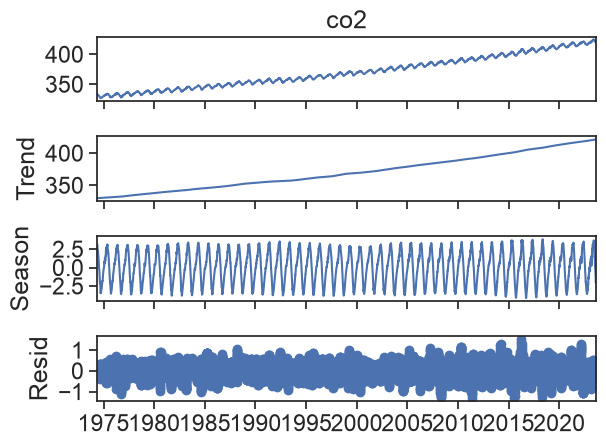

In [3]:
res = STL(df['co2'], period=365).fit()
res.plot();

A possible downside of STL is the fact that it assumes an additive model. If the seasonal oscillations in your data increase with the value of the series, then most probably a multiplicative model would be best for you. How to use STL then? One can take the logarithm of the series, since for a multiplicative model

$$
Y(t) = T(t) \times S(t) \times e(t)
$$

taking the logarithms yields

$$
\log(Y) = \log(T) + \log(S) + \log(e).
$$

We can now use STL since our model looks like additive now. After using STL, one can exponentiate the results to reverse the logarithm operation.

## MSTL

Some series have more than one seasonal cycle. Hourly temperature has a daily cycle and an annual cycle. Hourly electricity demand has a daily cycle, a weekly cycle (less demand on weekends), and an annual cycle on top of that. MSTL (Multiple STL) handles this by running STL once for each period, from the shortest to the longest. Before each run, it subtracts the other seasonal components estimated so far, and it repeats the process a couple of times. Just like in STL, you have to tell it the periods beforehand.

A daily cycle and an annual cycle are hard to see in the same graph: a year has 8760 hours, so the daily cycle becomes a solid band. To see what MSTL does without distractions, let's build a synthetic hourly series with a daily cycle (a sine wave) and a weekly cycle (a drop on weekends), plus a slow trend and noise. Because we built it, we know the true components and can check whether MSTL recovers them.

In [4]:
#| code-summary: "build a synthetic series with daily and weekly cycles"
rng = np.random.default_rng(0)
time = pd.date_range("2025-01-06", periods=24*7*6, freq="h")  # 6 weeks, starting on a Monday
t = np.arange(len(time))
true_trend = 20 + 3 * t / len(t)
true_daily = 3 * np.sin(2 * np.pi * (t / 24 - 0.25))     # one cycle every 24 hours
weekend = time.dayofweek >= 5                             # Saturday and Sunday
true_weekly = np.where(weekend, -4.0, 1.6)
true_weekly = true_weekly - true_weekly.mean()           # one cycle every 168 hours
series = pd.Series(true_trend + true_daily + true_weekly + rng.normal(0, 0.7, len(t)), index=time)

In [5]:
#| code-fold: false
res = MSTL(series, periods=(24, 24*7)).fit()
res.seasonal.columns

Index(['seasonal_24', 'seasonal_168'], dtype='str')

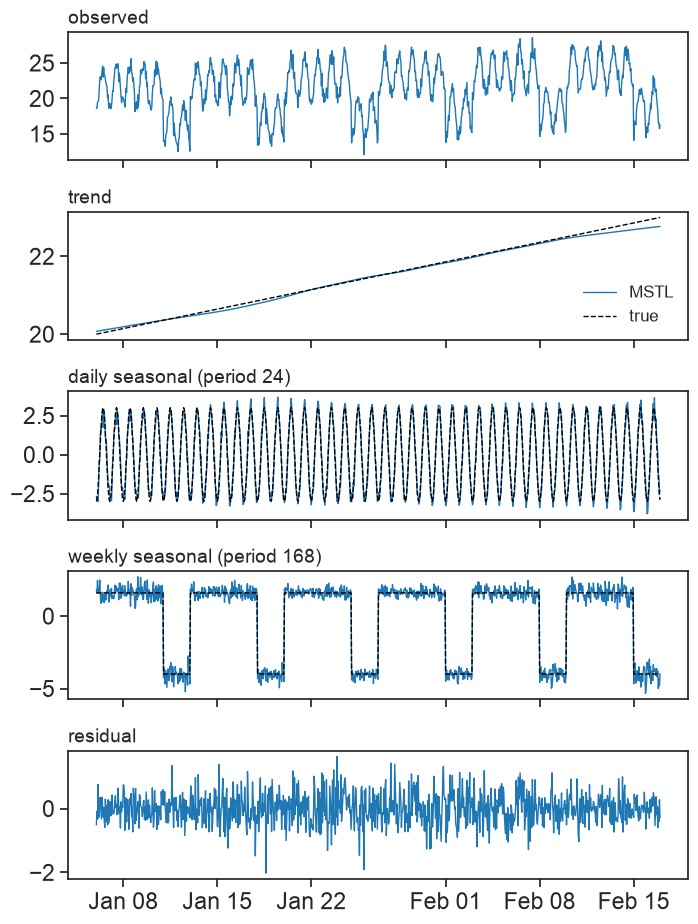

In [6]:
#| code-summary: "plot MSTL components against the true ones"
fig, ax = plt.subplots(5, 1, figsize=(8, 11), sharex=True)
fig.subplots_adjust(hspace=0.4)
panels = [("observed", series, None),
          ("trend", res.trend, true_trend),
          ("daily seasonal (period 24)", res.seasonal['seasonal_24'], true_daily),
          ("weekly seasonal (period 168)", res.seasonal['seasonal_168'], true_weekly),
          ("residual", res.resid, None)]
for axx, (label, estimated, true) in zip(ax, panels):
    axx.plot(estimated, color="tab:blue", lw=1, label="MSTL")
    if true is not None:
        axx.plot(time, true, color="black", ls="--", lw=1, label="true")
    axx.set_title(label, loc='left', fontsize=14)
ax[1].legend(frameon=False, loc="lower right", fontsize=12)
ax[4].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"));

MSTL recovers both cycles, even though the weekly one is not a sine wave at all. For real hourly temperature measured over several years, the call would be `MSTL(data, periods=(24, 24*365))`.